[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.1/Problem_1.14.ipynb)

# Chapter 1, Problem 14 — the low-velocity limits

**Problem (paraphrased).** Suppose the velocity $v$ of $\bar{\mathcal O}$ relative to $\mathcal O$ is small, $|v| \ll 1$. Show that the time dilation, Lorentz contraction and velocity-addition formulae can be approximated by

- **(a)** $\Delta t \approx \left(1 + \tfrac12 v^2\right)\Delta\bar t$,
- **(b)** $\Delta x \approx \left(1 - \tfrac12 v^2\right)\Delta\bar x$,
- **(c)** $w' \approx w + v - wv(w+v)$ (with $|w| \ll 1$ as well).

What are the relative errors in these approximations when $|v| = w = 0.1$?

**The exact formulae** (§1.8, §1.10):
$$
\Delta t = \frac{\Delta\bar t}{\sqrt{1-v^2}}\ \ \text{(1.8)},\qquad
\Delta x = \Delta\bar x\,\sqrt{1-v^2}\ \ \text{(1.11)},\qquad
w' = \frac{w + v}{1 + wv}\ \ \text{(1.13)}.
$$
Here $\Delta\bar t$ is the proper time on $\bar{\mathcal O}$'s clock, $\Delta\bar x$ the proper length of a rod at rest in $\bar{\mathcal O}$, and $w$ a velocity measured in $\bar{\mathcal O}$.

**Tool: the binomial expansion.** For $|\epsilon| < 1$,
$$
(1 + \epsilon)^n = 1 + n\epsilon + \frac{n(n-1)}{2}\epsilon^2 + \frac{n(n-1)(n-2)}{6}\epsilon^3 + \cdots
$$

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## (a) Time dilation

Use the binomial expansion with $\epsilon = -v^2$, $n = -\tfrac12$:
$$
(1 - v^2)^{-1/2} = 1 + \left(-\tfrac12\right)(-v^2) + \frac{(-\frac12)(-\frac32)}{2}v^4 + \cdots = 1 + \tfrac12 v^2 + \tfrac38 v^4 + \cdots
$$
Dropping $O(v^4)$:
$$
\boxed{\Delta t \approx \left(1 + \tfrac12 v^2\right)\Delta\bar t}
$$
The first neglected term, $\tfrac38 v^4$, sets the size of the error.

## (b) Lorentz contraction

$\epsilon = -v^2$, $n = +\tfrac12$:
$$
(1 - v^2)^{1/2} = 1 - \tfrac12 v^2 + \frac{(\frac12)(-\frac12)}{2}v^4 + \cdots = 1 - \tfrac12 v^2 - \tfrac18 v^4 + \cdots
$$
$$
\boxed{\Delta x \approx \left(1 - \tfrac12 v^2\right)\Delta\bar x}
$$

## (c) Velocity addition

Expand the denominator with $\epsilon = wv$ (small, since both $|w|$ and $|v|$ are), $n = -1$:
$$
\frac{1}{1 + wv} = 1 - wv + (wv)^2 - \cdots
$$
$$
w' = (w+v)\left[1 - wv + (wv)^2 - \cdots\right] = w + v - wv(w + v) + w^2v^2(w+v) - \cdots
$$
Count orders in the small quantities $w, v$: $w+v$ is first order, $wv(w+v)$ is third order, and the next term, $w^2v^2(w+v)$, is fifth order (there are no even-order terms). Keeping everything through third order:
$$
\boxed{w' \approx w + v - wv(w + v)}
$$
The leading part $w + v$ is Galilean addition; $-wv(w+v)$ is the first relativistic correction. The error is fifth order, i.e. a *relative* error of order $w v$ squared.

In [2]:
import sympy as sp
v, w = sp.symbols("v w", real=True)
print("(1−v²)^(−1/2) =", sp.series((1 - v**2)**sp.Rational(-1, 2), v, 0, 7))
print("(1−v²)^(+1/2) =", sp.series((1 - v**2)**sp.Rational(1, 2), v, 0, 7))
eps = sp.symbols("epsilon")
wp = ((w + v) / (1 + w*v)).subs({w: eps*w, v: eps*v})          # tag each small quantity with ε
print("w' =", sp.expand(sp.series(wp, eps, 0, 6).removeO().subs(eps, 1)))

(1−v²)^(−1/2) = 1 + v**2/2 + 3*v**4/8 + 5*v**6/16 + O(v**7)
(1−v²)^(+1/2) = 1 - v**2/2 - v**4/8 - v**6/16 + O(v**7)
w' = v**3*w**2 + v**2*w**3 - v**2*w - v*w**2 + v + w


## Relative errors at $|v| = w = 0.1$

Define the relative error as (approximate − exact)/exact.

**(a)** exact $\gamma = 1/\sqrt{0.99} = 1.0050378$; approx $1.005$:
$$
\frac{1.005 - 1.0050378}{1.0050378} \approx -3.8\times10^{-5}\quad(\approx -\tfrac38 v^4 = -3.75\times10^{-5}).
$$

**(b)** exact $\sqrt{0.99} = 0.9949874$; approx $0.995$:
$$
\frac{0.995 - 0.9949874}{0.9949874} \approx +1.3\times10^{-5}\quad(\approx +\tfrac18 v^4 = 1.25\times10^{-5}).
$$

**(c)** For $w = v = 0.1$: exact $w' = 0.2/1.01 = 0.1980198$; approx $0.1 + 0.1 - 0.01\times0.2 = 0.198$:
$$
\frac{0.198 - 0.1980198}{0.1980198} \approx -1.0\times10^{-4}\quad(\approx -w^2v^2 = -10^{-4}).
$$
If $v = -0.1$ (with $w = 0.1$), then $w' = 0$ exactly, and the approximation also gives $0 - (-0.01)(0) = 0$: zero error.

So at 10% of light speed the approximations are good to about 1 part in $10^4$–$10^5$, and the corrections themselves are only $\sim v^2/2 = 0.5\%$.

In [3]:
import numpy as np
V = W = 0.1
exact = {"(a) Δt/Δt̄": 1/np.sqrt(1 - V**2), "(b) Δx/Δx̄": np.sqrt(1 - V**2), "(c) w'": (W + V)/(1 + W*V)}
approx = {"(a) Δt/Δt̄": 1 + V**2/2, "(b) Δx/Δx̄": 1 - V**2/2, "(c) w'": W + V - W*V*(W + V)}
for k in exact:
    rel = (approx[k] - exact[k]) / exact[k]
    print(f"{k:12s} exact = {exact[k]:.8f}   approx = {approx[k]:.8f}   relative error = {rel:+.3e}")
print("\nv = −0.1, w = 0.1:  exact w' =", (W - 0.1)/(1 - W*0.1), " approx =", W - 0.1 - W*(-0.1)*(W - 0.1))

(a) Δt/Δt̄   exact = 1.00503782   approx = 1.00500000   relative error = -3.763e-05
(b) Δx/Δx̄   exact = 0.99498744   approx = 0.99500000   relative error = +1.263e-05
(c) w'       exact = 0.19801980   approx = 0.19800000   relative error = -1.000e-04

v = −0.1, w = 0.1:  exact w' = 0.0  approx = 0.0


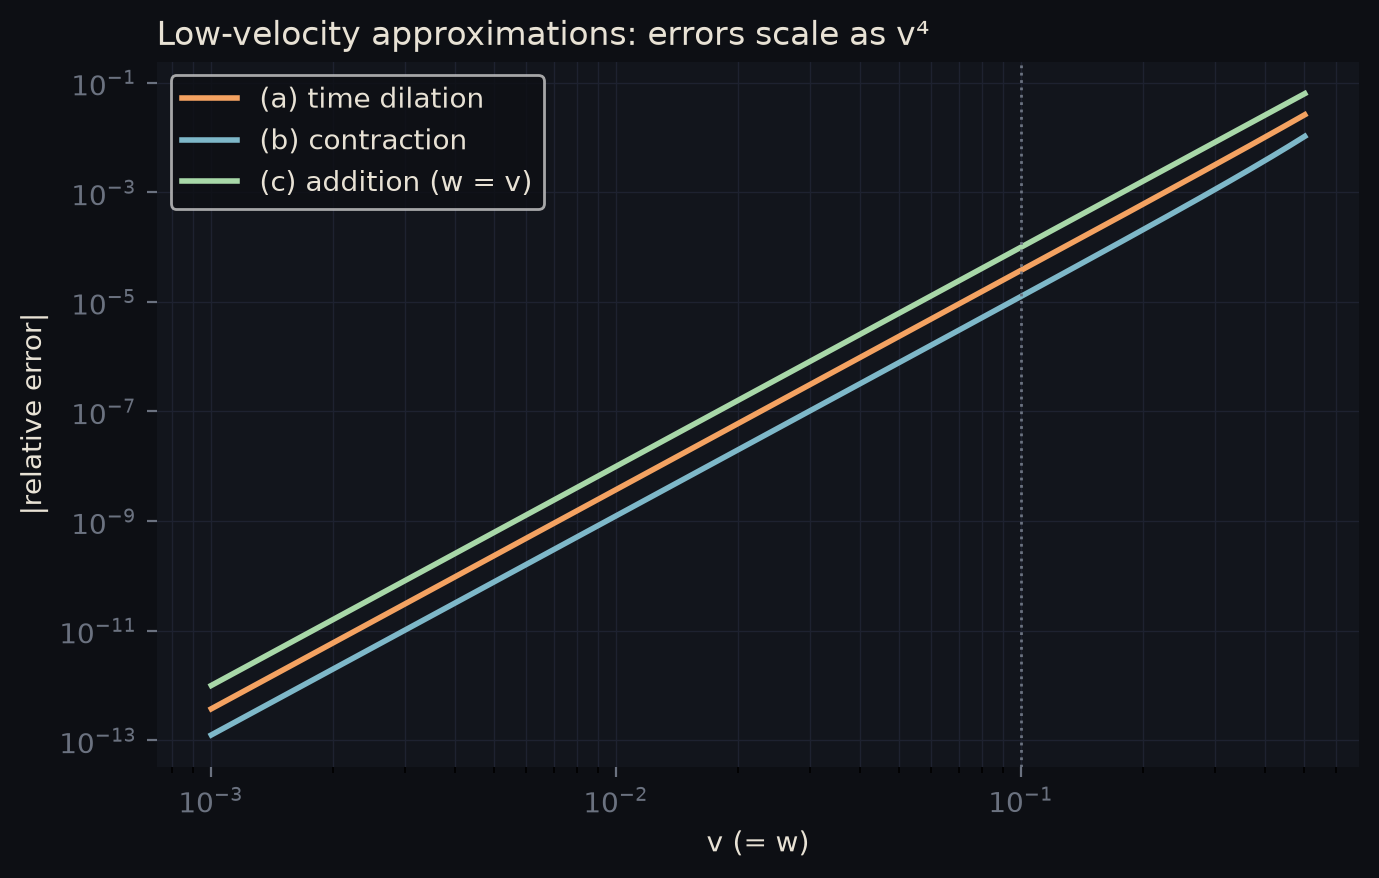

In [4]:
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'
vv = np.logspace(-3, -0.3, 200)
errs = {
    "(a) time dilation": np.abs((1 + vv**2/2)*np.sqrt(1 - vv**2) - 1),
    "(b) contraction": np.abs((1 - vv**2/2)/np.sqrt(1 - vv**2) - 1),
    "(c) addition (w = v)": np.abs((2*vv - 2*vv**3)*(1 + vv**2)/(2*vv) - 1),
}
fig, ax = plt.subplots(figsize=(7, 4.5)); fig.patch.set_facecolor(COLORS["bg"]); ax.set_facecolor(COLORS["panel"])
for (k, e), c in zip(errs.items(), ("amber", "teal", "green")):
    ax.loglog(vv, e, color=COLORS[c], lw=2, label=k)
ax.axvline(0.1, color=COLORS["grey"], ls=":", lw=1)
ax.set_xlabel("v (= w)", color=COLORS["text"]); ax.set_ylabel("|relative error|", color=COLORS["text"])
ax.set_title("Low-velocity approximations: errors scale as v⁴", color=COLORS["text"], loc="left")
ax.tick_params(colors=COLORS["grey"]); ax.grid(color=COLORS["grid"], which="both", lw=0.5)
for s in ax.spines.values(): s.set_visible(False)
leg = ax.legend(); leg.get_frame().set_facecolor(COLORS["bg"])
for t in leg.get_texts(): t.set_color(COLORS["text"])
plt.tight_layout(); plt.show()